# Machine Learning Capstone — Final Review Notebook

**Course:** 23CSE301 Machine Learning | **Academic Year:** 2026–27  
**Review 2 scope:** Classification Part B + complete Clustering track.  
This notebook also retains the Review 1 regression and Classification Part A work so the classification comparison can include all 10 algorithms.

> **Run instructions:** Keep `coaster_db.csv`, `pokemon.csv`, and `starbucks_drinkMenu_expanded.csv` in the same folder as this notebook (or in a `data/` folder). Run cells from top to bottom. Outputs are generated from the supplied datasets; interpret the plots and results yourself for the viva.

## Review 2 notebook checklist

- [x] Classification Part A: 5 required models retained from Review 1.
- [x] Classification Part B: Random Forest, AdaBoost, Gradient Boosting, Decision Tree Bagging, and MLP.
- [x] One consolidated comparison table for all 10 classifiers: Accuracy, weighted Precision/Recall/F1, ROC-AUC.
- [x] Confusion matrices, ROC curves, cross-validation for the top two classifiers, and hyperparameter tuning with metric comparison.
- [x] Clustering: K-Means and Agglomerative Hierarchical clustering.
- [x] K-Means elbow curve, hierarchical dendrograms for multiple linkage strategies, all three clustering metrics.
- [x] PCA 2D visualisations for each clustering algorithm and t-SNE visualisation.
- [x] Fixed random seed, modular preprocessing pipelines, and dataset-path checks.

**Outside-notebook deliverables still need to be completed separately:** README with setup/results, `requirements.txt` or `environment.yml`, meaningful GitHub commits, presentation, and viva preparation. These cannot honestly be marked complete by an `.ipynb` file alone.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, KFold, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# regressors
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

# classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

## 1. data audit

In [2]:
# Find the supplied dataset locally or in a Kaggle environment.
candidate_paths = [
    "coaster_db.csv",
    "data/coaster_db.csv",
    "../data/coaster_db.csv",
]
data_path = next((p for p in candidate_paths if os.path.exists(p)), None)
if data_path is None and os.path.isdir("/kaggle/input"):
    for root, dirs, files in os.walk("/kaggle/input"):
        match = next((f for f in files if f.lower() == "coaster_db.csv"), None)
        if match:
            data_path = os.path.join(root, match)
            break
if data_path is None:
    raise FileNotFoundError("coaster_db.csv not found. Place it beside this notebook or in data/.")

df = pd.read_csv(data_path)
print(f"loaded dataset from: {data_path}")

# standardizing column names
col_map = {col.lower(): col for col in df.columns}
speed_col = col_map.get('speed_mph', 'speed_mph')
height_col = col_map.get('height_ft', 'height_ft')
length_col = col_map.get('length_ft', 'Length' if 'Length' in df.columns else 'length_ft')
inversions_col = col_map.get('inversions_clean', 'Inversions_clean' if 'Inversions_clean' in df.columns else 'inversions_clean')
gforce_col = col_map.get('gforce_clean', 'Gforce_clean' if 'Gforce_clean' in df.columns else 'gforce_clean')
type_col = col_map.get('type_main', 'Type_Main' if 'Type_Main' in df.columns else 'type_main')

# The supplied coaster file stores Length as strings such as "600 ft (180 m)".
# Extract the first numeric measurement so EDA and modelling use numeric values.
for numeric_col in [speed_col, height_col, length_col, inversions_col, gforce_col]:
    if numeric_col in df.columns:
        if df[numeric_col].dtype == "object":
            df[numeric_col] = pd.to_numeric(
                df[numeric_col].astype(str).str.extract(r"([-+]?\d*\.?\d+)")[0],
                errors="coerce"
            )
        else:
            df[numeric_col] = pd.to_numeric(df[numeric_col], errors="coerce")

print("\n--- shape ---")
print(df.shape)

print("\n--- dtypes ---")
print(df.dtypes)

print("\n--- missing values ---")
print(df.isnull().sum())

print("\n--- duplicates ---")
print(df.duplicated().sum())

print(f"\n--- target stats ({speed_col}) ---")
print(df[speed_col].describe())

loaded dataset from: coaster_db.csv

--- shape ---
(1087, 56)

--- dtypes ---
coaster_name                         str
Length                           float64
Speed                                str
Location                             str
Status                               str
Opening date                         str
Type                                 str
Manufacturer                         str
Height restriction                   str
Model                                str
Height                               str
Inversions                       float64
Lift/launch system                   str
Cost                                 str
Trains                               str
Park section                         str
Duration                             str
Capacity                             str
G-force                              str
Designer                             str
Max vertical angle                   str
Drop                                 str
Soft opening date   

## 2. EDA

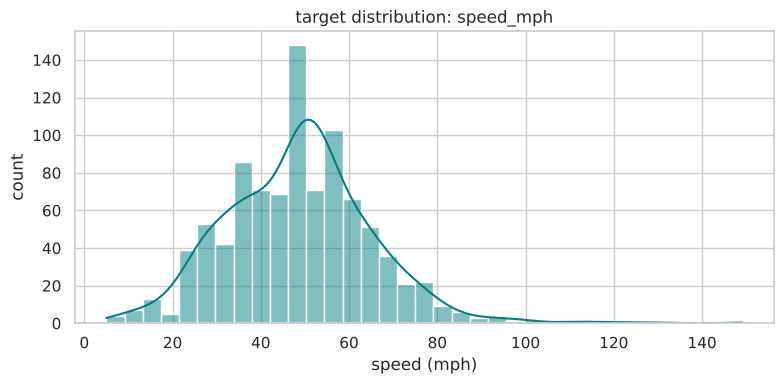

In [3]:
# target distribution
plt.figure(figsize=(8, 4))
sns.histplot(df[speed_col].dropna(), kde=True, color="teal")
plt.title(f"target distribution: {speed_col}")
plt.xlabel("speed (mph)")
plt.ylabel("count")
plt.tight_layout()
plt.show()

**target check:** speed is pretty normal looking around 48 mph. no transformation needed.

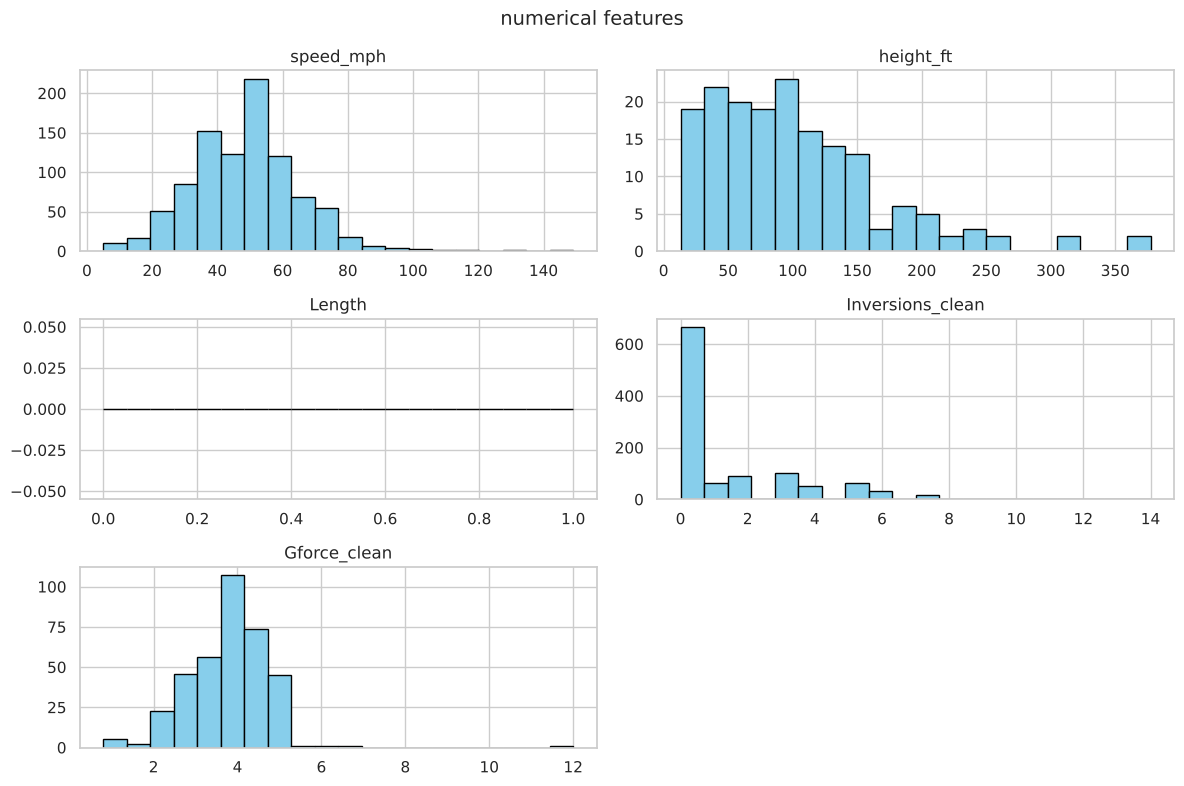

In [4]:
# numerical distributions
num_cols_eda = [c for c in [speed_col, height_col, length_col, inversions_col, gforce_col] if c in df.columns]
df[num_cols_eda].hist(figsize=(12, 8), bins=20, color="skyblue", edgecolor="black")
plt.suptitle("numerical features", fontsize=14)
plt.tight_layout()
plt.show()

**feature check:** height and length are right skewed from a few really big coasters. inversions is mostly zeros. will clean up extreme outliers before training.

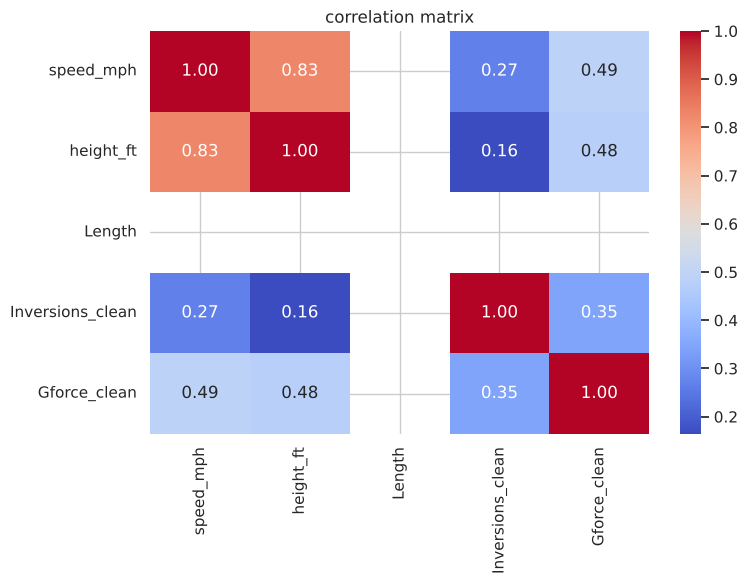

In [5]:
# correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols_eda].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("correlation matrix")
plt.tight_layout()
plt.show()

**correlations:** height and length correlate with speed and each other, so linear models might see collinearity. ridge and lasso should help.

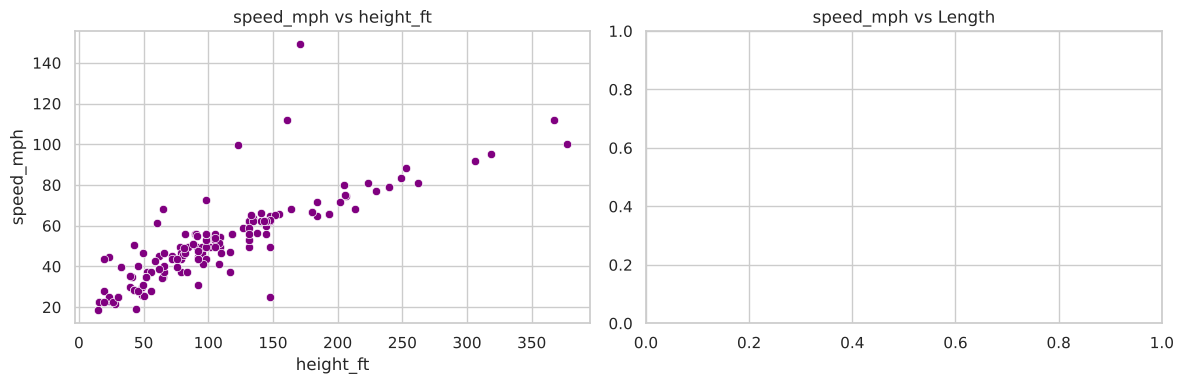

In [6]:
# scatter plots
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
if height_col in df.columns:
    sns.scatterplot(data=df, x=height_col, y=speed_col, ax=axes[0], color="purple")
    axes[0].set_title(f"{speed_col} vs {height_col}")
if length_col in df.columns:
    sns.scatterplot(data=df, x=length_col, y=speed_col, ax=axes[1], color="orange")
    axes[1].set_title(f"{speed_col} vs {length_col}")
plt.tight_layout()
plt.show()

**scatter plots:** positive trend overall. variance gets wider at higher values so non linear models should perform well here.

Target speed looks normal around 48 mph. Height and length correlate with speed and with each other, and feature skew justifies both outlier checks and non linear models.

## 3. preprocessing

In [7]:
# drop rows without target
df_clean = df.dropna(subset=[speed_col]).copy()

# drop duplicate coasters
dup_cols = [c for c in ["Coaster_Name", "Location"] if c in df_clean.columns]
if dup_cols:
    before = len(df_clean)
    df_clean = df_clean.drop_duplicates(subset=dup_cols).reset_index(drop=True)
    print(f"dropped {before - len(df_clean)} duplicate coaster rows")

dropped 696 duplicate coaster rows


**outliers:** using iqr to flag bad rows. only dropping if a row is an outlier on multiple features so we keep legitimate records.

In [8]:
# outlier check (IQR rule) on key numeric columns
outlier_check_cols = [c for c in [speed_col, height_col, length_col] if c in df_clean.columns]
outlier_flags = pd.DataFrame(index=df_clean.index)

for c in outlier_check_cols:
    q1, q3 = df_clean[c].quantile(0.25), df_clean[c].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_flags[c] = (df_clean[c] < lower) | (df_clean[c] > upper)
    print(f"{c}: {outlier_flags[c].sum()} rows outside [{lower:.1f}, {upper:.1f}]")

# flag rows that are outliers on 2+ of the checked columns as likely data-entry issues
multi_outlier_mask = outlier_flags.sum(axis=1) >= 2
print(f"\nrows flagged as outliers on 2+ features (dropped): {multi_outlier_mask.sum()}")
df_clean = df_clean.loc[~multi_outlier_mask].reset_index(drop=True)

speed_mph: 7 rows outside [10.7, 81.6]
height_ft: 2 rows outside [-32.8, 229.6]
Length: 0 rows outside [nan, nan]

rows flagged as outliers on 2+ features (dropped): 1


In [9]:
# steepness feature
if height_col in df_clean.columns and length_col in df_clean.columns:
    df_clean["height_to_length_ratio"] = df_clean[height_col] / (df_clean[length_col] + 1)
    ratio_col = "height_to_length_ratio"
else:
    ratio_col = None

**new feature:** adding height to length ratio to capture steepness. gives tree models extra signal beyond raw dimensions.

In [10]:
num_features = [c for c in [height_col, length_col, inversions_col, ratio_col] if c and c in df_clean.columns]
cat_features = [c for c in [type_col] if c in df_clean.columns]

X = df_clean[num_features + cat_features]
y = df_clean[speed_col]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

def get_preprocessor():
    transformers = []
    if num_features:
        num_transformer = Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ])
        transformers.append(("num", num_transformer, num_features))
    if cat_features:
        cat_transformer = Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ])
        transformers.append(("cat", cat_transformer, cat_features))
    return ColumnTransformer(transformers=transformers)

print(f"train shape: {X_train.shape}, test shape: {X_test.shape}")

train shape: (192, 5), test shape: (48, 5)


Everything is inside a Pipeline so transformation fits only on train data to prevent leakage.

## 4. regression

Running all 10 regressors: Linear, Ridge, Lasso, ElasticNet, Poly, Decision Tree, Random Forest, Gradient Boosting, SVR, and KNN.

In [11]:
# Polynomial Regression is PolynomialFeatures -> LinearRegression, degree 2 by default
poly_reg = Pipeline(steps=[
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("lin", LinearRegression())
])

regressors = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(random_state=SEED),
    "Lasso": Lasso(random_state=SEED),
    "ElasticNet": ElasticNet(random_state=SEED),
    "Polynomial Regression (deg=2)": poly_reg,
    "Decision Tree Regressor": DecisionTreeRegressor(random_state=SEED),
    "Random Forest Regressor": RandomForestRegressor(random_state=SEED),
    "Gradient Boosting Regressor": GradientBoostingRegressor(random_state=SEED),
    "SVR": SVR(),
    "KNN Regressor": KNeighborsRegressor()
}

results = []
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)

for name, reg in regressors.items():
    pipe = Pipeline(steps=[("prep", get_preprocessor()), ("reg", reg)])

    cv_scores = cross_val_score(pipe, X_train, y_train, cv=kf, scoring="r2")
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)

    results.append({
        "Model": name,
        "Mean CV R2": cv_scores.mean(),
        "Test R2": r2_score(y_test, preds),
        "RMSE": np.sqrt(mean_squared_error(y_test, preds)),
        "MAE": mean_absolute_error(y_test, preds)
    })

results_df = pd.DataFrame(results).sort_values(by="Test R2", ascending=False)
print(results_df.to_string(index=False))

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for 

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for 

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for 

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for 

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for 

...

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for 

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for 

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for 

                        Model  Mean CV R2   Test R2      RMSE       MAE
      Decision Tree Regressor    0.135124  0.142179  9.586232  8.193053
  Gradient Boosting Regressor    0.219702  0.130496  9.651291  8.104875
      Random Forest Regressor    0.213634  0.129416  9.657283  8.209617
                          SVR    0.136844  0.123366  9.690781  7.894243
                   ElasticNet    0.199783  0.075638  9.951092  8.171960
Polynomial Regression (deg=2)    0.084653  0.023130 10.229822  8.514087
                        Lasso    0.214719 -0.005410 10.378179  8.512663
                        Ridge    0.203763 -0.069525 10.703973  8.776473
            Linear Regression    0.200648 -0.072922 10.720959  8.794086
                KNN Regressor    0.094189 -0.793816 13.862404 11.440417


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


Tuning the top two models: Random Forest and Gradient Boosting.

In [12]:
# hyperparameter tuning -- model 1: Random Forest Regressor
rf_pipe = Pipeline(steps=[("prep", get_preprocessor()), ("reg", RandomForestRegressor(random_state=SEED))])

rf_param_grid = {
    "reg__n_estimators": [50, 100, 200],
    "reg__max_depth": [None, 10, 20],
    "reg__min_samples_split": [2, 5]
}

grid_rf = GridSearchCV(rf_pipe, rf_param_grid, cv=kf, scoring="r2", n_jobs=-1)
grid_rf.fit(X_train, y_train)

best_rf = grid_rf.best_estimator_
tuned_rf_preds = best_rf.predict(X_test)

baseline_rf_r2 = results_df.loc[results_df["Model"] == "Random Forest Regressor", "Test R2"].values[0]
tuned_rf_r2 = r2_score(y_test, tuned_rf_preds)

print("Random Forest -- best params:", grid_rf.best_params_)
print(f"baseline test r2: {baseline_rf_r2:.4f}  ->  tuned test r2: {tuned_rf_r2:.4f}  "
      f"(delta: {tuned_rf_r2 - baseline_rf_r2:+.4f})")
print(f"tuned test rmse: {np.sqrt(mean_squared_error(y_test, tuned_rf_preds)):.4f}")

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for 

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for 

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for 

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for 

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


...

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for 

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for 

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for 

Random Forest -- best params: {'reg__max_depth': None, 'reg__min_samples_split': 5, 'reg__n_estimators': 100}
baseline test r2: 0.1294  ->  tuned test r2: 0.1208  (delta: -0.0086)
tuned test rmse: 9.7048


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


In [13]:
# hyperparameter tuning -- model 2: Gradient Boosting Regressor
gb_pipe = Pipeline(steps=[("prep", get_preprocessor()), ("reg", GradientBoostingRegressor(random_state=SEED))])

gb_param_grid = {
    "reg__n_estimators": [100, 200],
    "reg__learning_rate": [0.05, 0.1, 0.2],
    "reg__max_depth": [2, 3, 4]
}

grid_gb = GridSearchCV(gb_pipe, gb_param_grid, cv=kf, scoring="r2", n_jobs=-1)
grid_gb.fit(X_train, y_train)

best_gb = grid_gb.best_estimator_
tuned_gb_preds = best_gb.predict(X_test)

baseline_gb_r2 = results_df.loc[results_df["Model"] == "Gradient Boosting Regressor", "Test R2"].values[0]
tuned_gb_r2 = r2_score(y_test, tuned_gb_preds)

print("Gradient Boosting -- best params:", grid_gb.best_params_)
print(f"baseline test r2: {baseline_gb_r2:.4f}  ->  tuned test r2: {tuned_gb_r2:.4f}  "
      f"(delta: {tuned_gb_r2 - baseline_gb_r2:+.4f})")
print(f"tuned test rmse: {np.sqrt(mean_squared_error(y_test, tuned_gb_preds)):.4f}")

# pick whichever tuned model is best on test R2 for the plots below
if tuned_gb_r2 >= tuned_rf_r2:
    best_overall = best_gb
    tuned_preds = tuned_gb_preds
    best_overall_name = "Gradient Boosting Regressor (tuned)"
else:
    best_overall = best_rf
    tuned_preds = tuned_rf_preds
    best_overall_name = "Random Forest Regressor (tuned)"

print(f"\nbest overall tuned model: {best_overall_name}")

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for 

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for 

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for 

...

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for 

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for 

Gradient Boosting -- best params: {'reg__learning_rate': 0.05, 'reg__max_depth': 2, 'reg__n_estimators': 200}
baseline test r2: 0.1305  ->  tuned test r2: 0.1214  (delta: -0.0091)
tuned test rmse: 9.7016

best overall tuned model: Gradient Boosting Regressor (tuned)


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Length' 'height_to_length_ratio']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


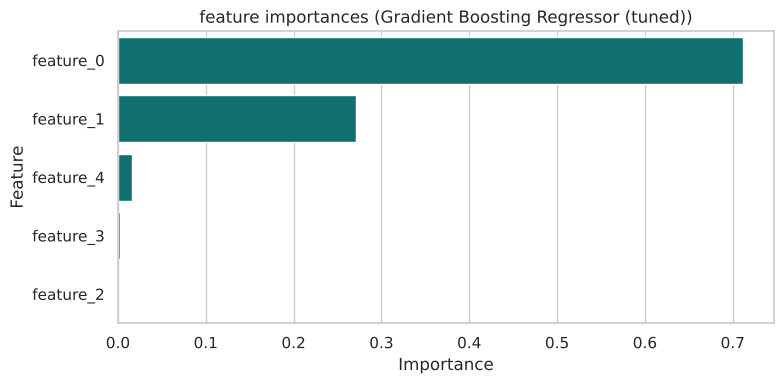

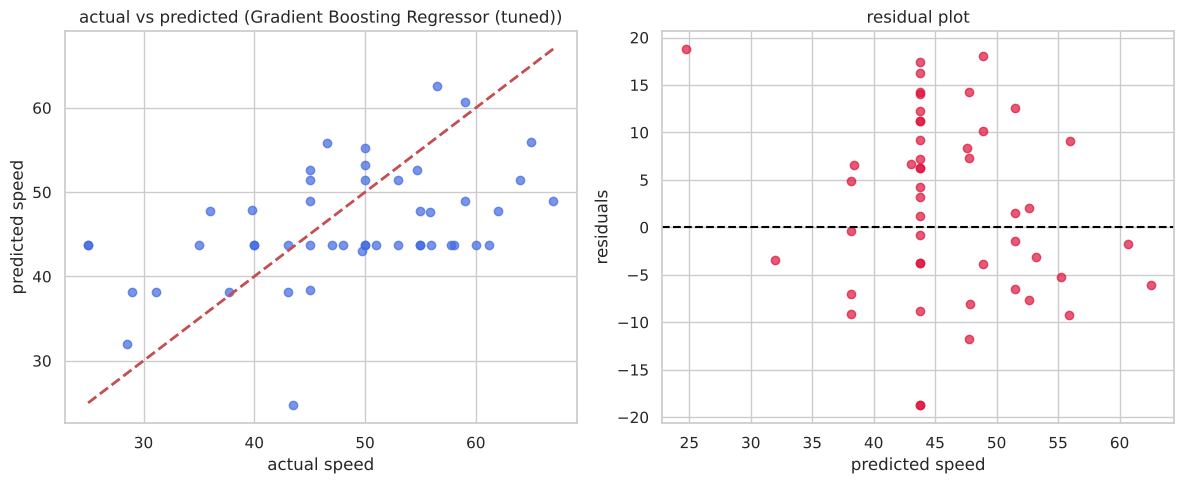

In [14]:
# feature importances & diagnostic plots (best overall tuned tree-based model)
all_feature_names = num_features.copy()
if cat_features and "cat" in best_overall.named_steps["prep"].named_transformers_:
    cat_encoder = best_overall.named_steps["prep"].named_transformers_["cat"].named_steps["encoder"]
    encoded_cat_cols = list(cat_encoder.get_feature_names_out(cat_features))
    all_feature_names.extend(encoded_cat_cols)

importances = best_overall.named_steps["reg"].feature_importances_
if len(all_feature_names) != len(importances):
    all_feature_names = [f"feature_{i}" for i in range(len(importances))]
feat_imp_df = pd.DataFrame({"Feature": all_feature_names, "Importance": importances}).sort_values(by="Importance", ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(data=feat_imp_df.head(10), x="Importance", y="Feature", color="teal")
plt.title(f"feature importances ({best_overall_name})")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(y_test, tuned_preds, alpha=0.7, color="royalblue")
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", lw=2)
axes[0].set_xlabel("actual speed")
axes[0].set_ylabel("predicted speed")
axes[0].set_title(f"actual vs predicted ({best_overall_name})")

residuals = y_test - tuned_preds
axes[1].scatter(tuned_preds, residuals, alpha=0.7, color="crimson")
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_xlabel("predicted speed")
axes[1].set_ylabel("residuals")
axes[1].set_title("residual plot")
plt.tight_layout()
plt.show()

## 5. classification track (Pokemon dataset)

Using Pokemon data for classification since predicting `is_legendary` is a natural binary task.

## 5.1 dataset audit

In [15]:
# Find the supplied Pokemon dataset locally or in Kaggle.
candidate_paths = ["pokemon.csv", "data/pokemon.csv", "../data/pokemon.csv"]
poke_path = next((p for p in candidate_paths if os.path.exists(p)), None)
if poke_path is None and os.path.isdir("/kaggle/input"):
    for root, dirs, files in os.walk("/kaggle/input"):
        match = next((f for f in files if f.lower() == "pokemon.csv"), None)
        if match:
            poke_path = os.path.join(root, match)
            break
if poke_path is None:
    raise FileNotFoundError("pokemon.csv not found. Place it beside this notebook or in data/.")

poke_df = pd.read_csv(poke_path)
print(f"loaded dataset from: {poke_path}")

print("\n--- shape ---")
print(poke_df.shape)

print("\n--- dtypes (first 20 cols) ---")
print(poke_df.dtypes.head(20))

print("\n--- missing values (nonzero only) ---")
missing = poke_df.isnull().sum()
print(missing[missing > 0])

print("\n--- duplicates ---")
print(poke_df.duplicated().sum())

print("\n--- target balance (is_legendary) ---")
print(poke_df["is_legendary"].value_counts())
print(poke_df["is_legendary"].value_counts(normalize=True))

loaded dataset from: pokemon.csv

--- shape ---
(801, 41)

--- dtypes (first 20 cols) ---
abilities               str
against_bug         float64
against_dark        float64
against_dragon      float64
against_electric    float64
against_fairy       float64
against_fight       float64
against_fire        float64
against_flying      float64
against_ghost       float64
against_grass       float64
against_ground      float64
against_ice         float64
against_normal      float64
against_poison      float64
against_psychic     float64
against_rock        float64
against_steel       float64
against_water       float64
attack                int64
dtype: object

--- missing values (nonzero only) ---
height_m            20
percentage_male     98
type2              384
weight_kg           20
dtype: int64

--- duplicates ---
0

--- target balance (is_legendary) ---
is_legendary
0    731
1     70
Name: count, dtype: int64
is_legendary
0    0.912609
1    0.087391
Name: proportion, dtype: float64


**class balance:** target is imbalanced with few legendaries. tracking precision recall and f1 instead of raw accuracy.

## 5.2 EDA

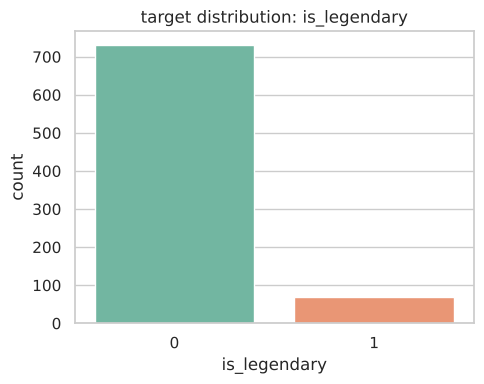

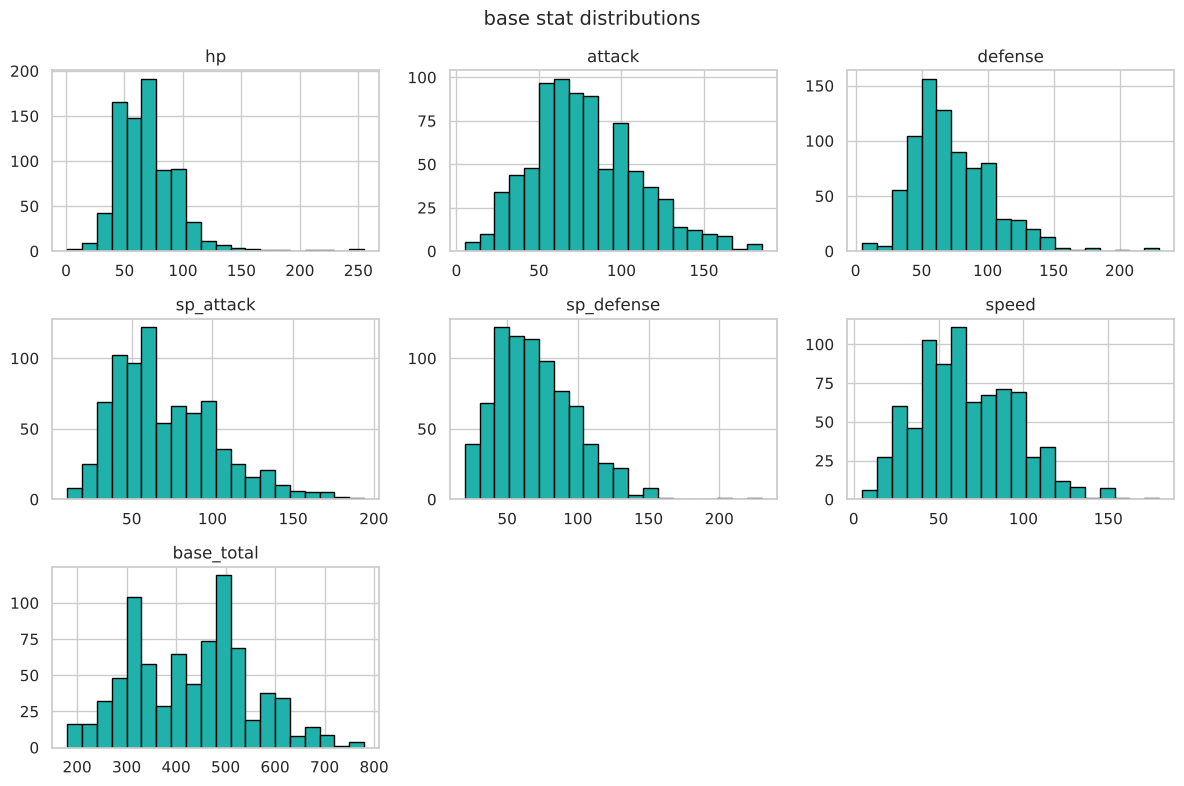

In [16]:
stat_cols = [c for c in ["hp", "attack", "defense", "sp_attack", "sp_defense", "speed", "base_total"]
             if c in poke_df.columns]

# class balance
plt.figure(figsize=(5, 4))
sns.countplot(data=poke_df, x="is_legendary", hue="is_legendary", palette="Set2", legend=False)
plt.title("target distribution: is_legendary")
plt.xlabel("is_legendary")
plt.ylabel("count")
plt.tight_layout()
plt.show()

# stat distributions
poke_df[stat_cols].hist(figsize=(12, 8), bins=20, color="lightseagreen", edgecolor="black")
plt.suptitle("base stat distributions", fontsize=14)
plt.tight_layout()
plt.show()

**stat distributions:** base stats skew right. legendary pokemon likely sit in the upper tail.

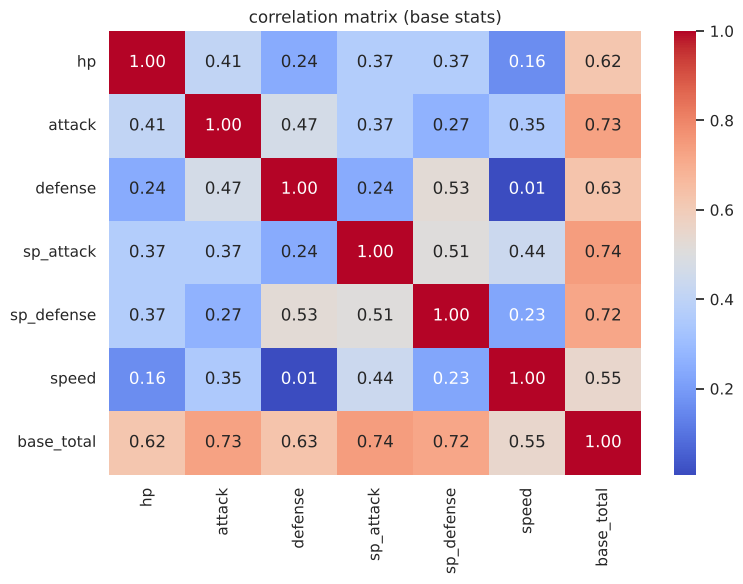

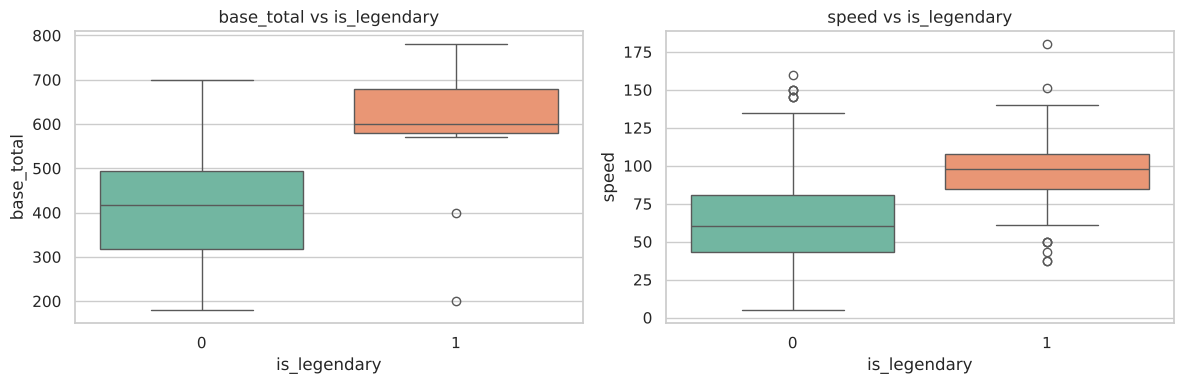

In [17]:
# correlation heatmap of stats
plt.figure(figsize=(8, 6))
sns.heatmap(poke_df[stat_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("correlation matrix (base stats)")
plt.tight_layout()
plt.show()

# stat vs legendary status
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=poke_df, x="is_legendary", y="base_total", ax=axes[0], hue="is_legendary",
            palette="Set2", legend=False)
axes[0].set_title("base_total vs is_legendary")
sns.boxplot(data=poke_df, x="is_legendary", y="speed", ax=axes[1], hue="is_legendary",
            palette="Set2", legend=False)
axes[1].set_title("speed vs is_legendary")
plt.tight_layout()
plt.show()

**stat comparisons:** stats correlate with each other. base total shows a clear split between regular and legendary pokemon.

## 5.3 preprocessing

In [18]:
poke_num_features = stat_cols + [c for c in ["height_m", "weight_kg", "capture_rate", "base_egg_steps"]
                                  if c in poke_df.columns]
poke_cat_features = [c for c in ["type1"] if c in poke_df.columns]

Xp = poke_df[poke_num_features + poke_cat_features].copy()
# capture_rate is sometimes stored as text with stray characters in this dataset -- coerce to numeric
if "capture_rate" in Xp.columns:
    Xp["capture_rate"] = pd.to_numeric(Xp["capture_rate"], errors="coerce")

yp = poke_df["is_legendary"]

Xp_train, Xp_test, yp_train, yp_test = train_test_split(
    Xp, yp, test_size=0.2, random_state=SEED, stratify=yp
)

def get_poke_preprocessor():
    transformers = []
    if poke_num_features:
        num_t = Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ])
        transformers.append(("num", num_t, poke_num_features))
    if poke_cat_features:
        cat_t = Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ])
        transformers.append(("cat", cat_t, poke_cat_features))
    return ColumnTransformer(transformers=transformers)

print(f"train shape: {Xp_train.shape}, test shape: {Xp_test.shape}")
print(f"train class balance:\n{yp_train.value_counts(normalize=True)}")

train shape: (640, 12), test shape: (161, 12)
train class balance:
is_legendary
0    0.9125
1    0.0875
Name: proportion, dtype: float64


Preprocessing is inside a pipeline to prevent leakage. Stratified split maintains class ratios.

## 5.4 classification models

In [19]:
poke_classifiers = {
    "Logistic Regression": LogisticRegression(random_state=SEED, max_iter=1000),
    "KNN Classifier": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB(),
    "Decision Tree Classifier": DecisionTreeClassifier(random_state=SEED),
    "SVC": SVC(random_state=SEED)
}

poke_cls_results = {}
skf_p = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

for name, clf in poke_classifiers.items():
    pipe_cls = Pipeline(steps=[("prep", get_poke_preprocessor()), ("clf", clf)])

    cv_acc = cross_val_score(pipe_cls, Xp_train, yp_train, cv=skf_p, scoring="accuracy")
    cv_f1 = cross_val_score(pipe_cls, Xp_train, yp_train, cv=skf_p, scoring="f1")
    pipe_cls.fit(Xp_train, yp_train)
    preds_c = pipe_cls.predict(Xp_test)

    poke_cls_results[name] = {
        "pipe": pipe_cls,
        "preds": preds_c,
        "row": {
            "Model": name,
            "Mean CV Accuracy": cv_acc.mean(),
            "Mean CV F1": cv_f1.mean(),
            "Test Accuracy": accuracy_score(yp_test, preds_c),
            "Precision": precision_score(yp_test, preds_c, zero_division=0),
            "Recall": recall_score(yp_test, preds_c, zero_division=0),
            "F1-Score": f1_score(yp_test, preds_c, zero_division=0)
        }
    }

poke_cls_df = pd.DataFrame([v["row"] for v in poke_cls_results.values()]).sort_values(by="F1-Score", ascending=False)
print(poke_cls_df.to_string(index=False))

                   Model  Mean CV Accuracy  Mean CV F1  Test Accuracy  Precision   Recall  F1-Score
Decision Tree Classifier          0.985938    0.919151       1.000000   1.000000 1.000000  1.000000
     Logistic Regression          0.982812    0.894487       0.981366   1.000000 0.785714  0.880000
          KNN Classifier          0.984375    0.904963       0.975155   1.000000 0.714286  0.833333
                     SVC          0.978125    0.863362       0.968944   1.000000 0.642857  0.782609
             Naive Bayes          0.479687    0.239764       0.509317   0.142857 0.928571  0.247619


Checking confusion matrices to track false negatives.

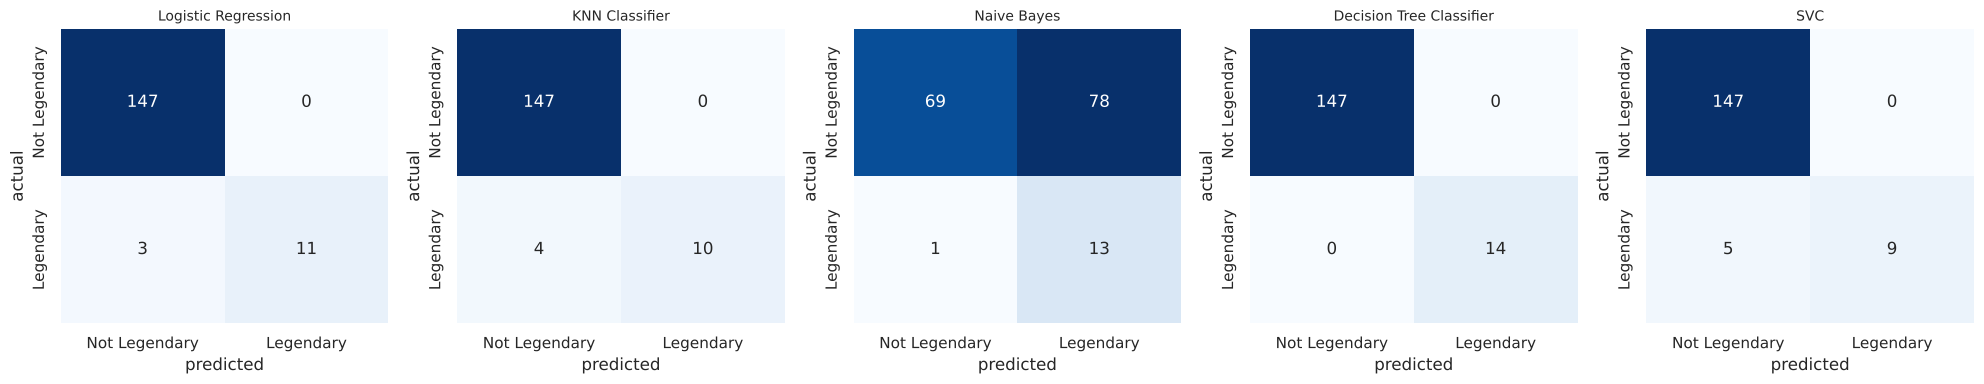


--- classification report (Logistic Regression) ---
               precision    recall  f1-score   support

Not Legendary       0.98      1.00      0.99       147
    Legendary       1.00      0.79      0.88        14

     accuracy                           0.98       161
    macro avg       0.99      0.89      0.93       161
 weighted avg       0.98      0.98      0.98       161


--- classification report (KNN Classifier) ---
               precision    recall  f1-score   support

Not Legendary       0.97      1.00      0.99       147
    Legendary       1.00      0.71      0.83        14

     accuracy                           0.98       161
    macro avg       0.99      0.86      0.91       161
 weighted avg       0.98      0.98      0.97       161


--- classification report (Naive Bayes) ---
               precision    recall  f1-score   support

Not Legendary       0.99      0.47      0.64       147
    Legendary       0.14      0.93      0.25        14

     accuracy        

In [20]:
fig, axes = plt.subplots(1, len(poke_cls_results), figsize=(4 * len(poke_cls_results), 4))
if len(poke_cls_results) == 1:
    axes = [axes]

for ax, (name, info) in zip(axes, poke_cls_results.items()):
    cm = confusion_matrix(yp_test, info["preds"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Not Legendary", "Legendary"],
                yticklabels=["Not Legendary", "Legendary"], ax=ax, cbar=False)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("predicted")
    ax.set_ylabel("actual")

plt.tight_layout()
plt.show()

for name, info in poke_cls_results.items():
    print(f"\n--- classification report ({name}) ---")
    print(classification_report(yp_test, info["preds"], target_names=["Not Legendary", "Legendary"]))

**results summary:** tree and margin based models handle the threshold split well. naive bayes drops in performance because features are correlated rather than independent.

In [21]:
from IPython.display import display
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, BaggingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import roc_auc_score, roc_curve

In [22]:
poke_classifiers_b = {
    "Random Forest": RandomForestClassifier(random_state=SEED),
    "AdaBoost": AdaBoostClassifier(random_state=SEED),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
    # note: older sklearn (<1.2) uses base_estimator= instead of estimator=
    "Bagging (Decision Tree)": BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=SEED), n_estimators=50, random_state=SEED),
    "MLP Classifier": MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu",
                                    max_iter=1000, random_state=SEED),
}

poke_cls_results_b = {}
for name, clf in poke_classifiers_b.items():
    pipe_b = Pipeline(steps=[("prep", get_poke_preprocessor()), ("clf", clf)])
    pipe_b.fit(Xp_train, yp_train)
    poke_cls_results_b[name] = {"pipe": pipe_b, "preds": pipe_b.predict(Xp_test)}
    print(f"trained: {name}")

trained: Random Forest
trained: AdaBoost


trained: Gradient Boosting
trained: Bagging (Decision Tree)


trained: MLP Classifier


In [23]:
def get_scores(pipe, X):
    # probability of the positive class; falls back to decision_function (e.g. SVC without probability=True)
    if hasattr(pipe, "predict_proba"):
        return pipe.predict_proba(X)[:, 1]
    return pipe.decision_function(X)

def evaluate_model(name, part, pipe, X, y):
    preds = pipe.predict(X)
    return {
        "Model": name,
        "Part": part,
        "Accuracy": accuracy_score(y, preds),
        "Precision": precision_score(y, preds, average="weighted", zero_division=0),
        "Recall": recall_score(y, preds, average="weighted", zero_division=0),
        "F1-Score": f1_score(y, preds, average="weighted", zero_division=0),
        "ROC-AUC": roc_auc_score(y, get_scores(pipe, X)),
        "F1 (Legendary)": f1_score(y, preds, pos_label=1, zero_division=0),
    }

all_cls = {**poke_cls_results, **poke_cls_results_b}
part_of = {n: "A" for n in poke_cls_results} | {n: "B" for n in poke_cls_results_b}

final_cls_df = (pd.DataFrame([evaluate_model(n, part_of[n], i["pipe"], Xp_test, yp_test)
                              for n, i in all_cls.items()])
                .sort_values(by=["F1-Score", "ROC-AUC"], ascending=False)
                .reset_index(drop=True))
final_cls_df.index += 1   # rank starts at 1
display(final_cls_df.round(4))

,Model,Part,Accuracy,Precision,Recall,F1-Score,ROC-AUC,F1 (Legendary)
1,Decision Tree Classifier,A,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
2,Gradient Boosting,B,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
3,Bagging (Decision Tree),B,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
4,Random Forest,B,0.9938,0.9938,0.9938,0.9937,1.0000,0.9630
5,AdaBoost,B,0.9938,0.9938,0.9938,0.9937,0.9995,0.9630
6,Logistic Regression,A,0.9814,0.9817,0.9814,0.9803,0.9917,0.8800
7,KNN Classifier,A,0.9752,0.9758,0.9752,0.9733,0.9266,0.8333
8,SVC,A,0.9689,0.9700,0.9689,0.9658,0.9840,0.7826
9,MLP Classifier,B,0.9565,0.9543,0.9565,0.9522,0.9840,0.6957
10,Naive Bayes,A,0.5093,0.9124,0.5093,0.6022,0.9181,0.2476


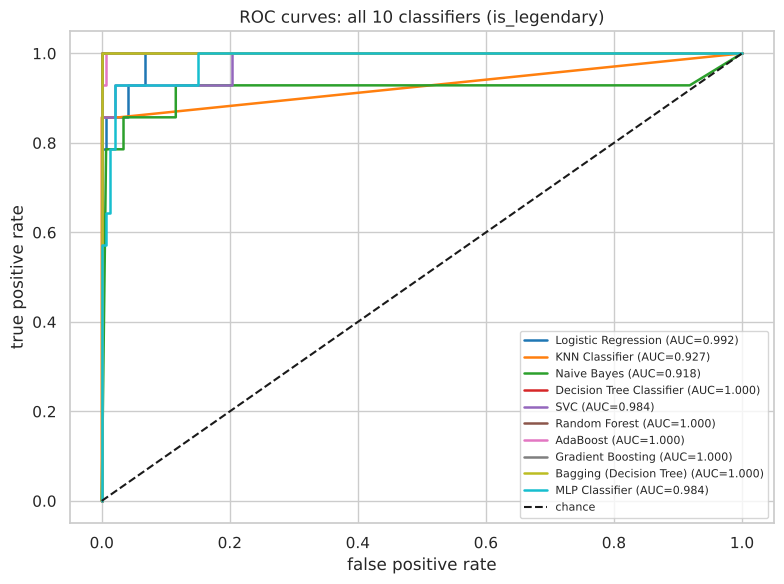

In [24]:
fig, ax = plt.subplots(figsize=(8, 6))
palette = sns.color_palette("tab10", len(all_cls))
for (name, info), color in zip(all_cls.items(), palette):
    scores = get_scores(info["pipe"], Xp_test)
    fpr, tpr, _ = roc_curve(yp_test, scores)
    ax.plot(fpr, tpr, color=color, lw=1.8, label=f"{name} (AUC={roc_auc_score(yp_test, scores):.3f})")
ax.plot([0, 1], [0, 1], "k--", label="chance")
ax.set_xlabel("false positive rate")
ax.set_ylabel("true positive rate")
ax.set_title("ROC curves: all 10 classifiers (is_legendary)")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

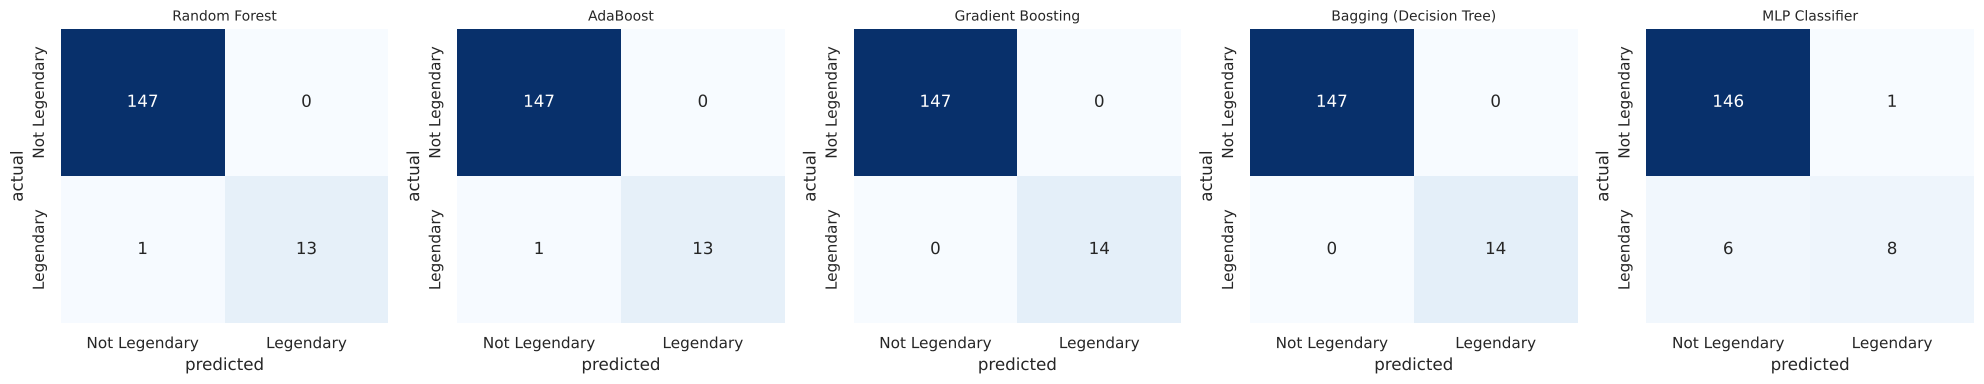


--- classification report (Random Forest) ---
               precision    recall  f1-score   support

Not Legendary       0.99      1.00      1.00       147
    Legendary       1.00      0.93      0.96        14

     accuracy                           0.99       161
    macro avg       1.00      0.96      0.98       161
 weighted avg       0.99      0.99      0.99       161


--- classification report (AdaBoost) ---
               precision    recall  f1-score   support

Not Legendary       0.99      1.00      1.00       147
    Legendary       1.00      0.93      0.96        14

     accuracy                           0.99       161
    macro avg       1.00      0.96      0.98       161
 weighted avg       0.99      0.99      0.99       161


--- classification report (Gradient Boosting) ---
               precision    recall  f1-score   support

Not Legendary       1.00      1.00      1.00       147
    Legendary       1.00      1.00      1.00        14

     accuracy              

In [25]:
fig, axes = plt.subplots(1, len(poke_cls_results_b), figsize=(4 * len(poke_cls_results_b), 4))
for ax, (name, info) in zip(axes, poke_cls_results_b.items()):
    cm = confusion_matrix(yp_test, info["preds"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Not Legendary", "Legendary"], yticklabels=["Not Legendary", "Legendary"])
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("predicted")
    ax.set_ylabel("actual")
plt.tight_layout()
plt.show()

for name, info in poke_cls_results_b.items():
    print(f"\n--- classification report ({name}) ---")
    print(classification_report(yp_test, info["preds"], target_names=["Not Legendary", "Legendary"]))

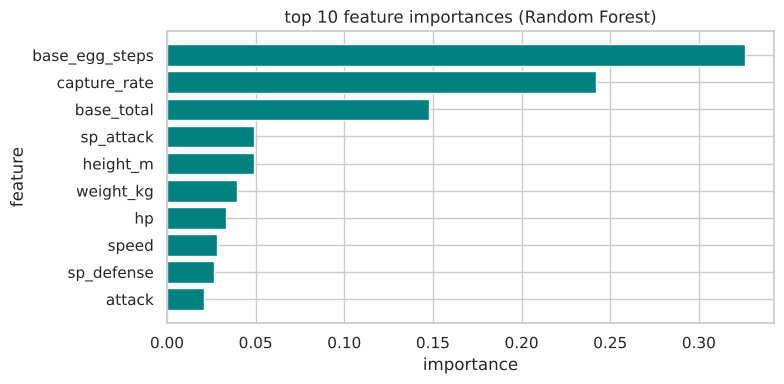

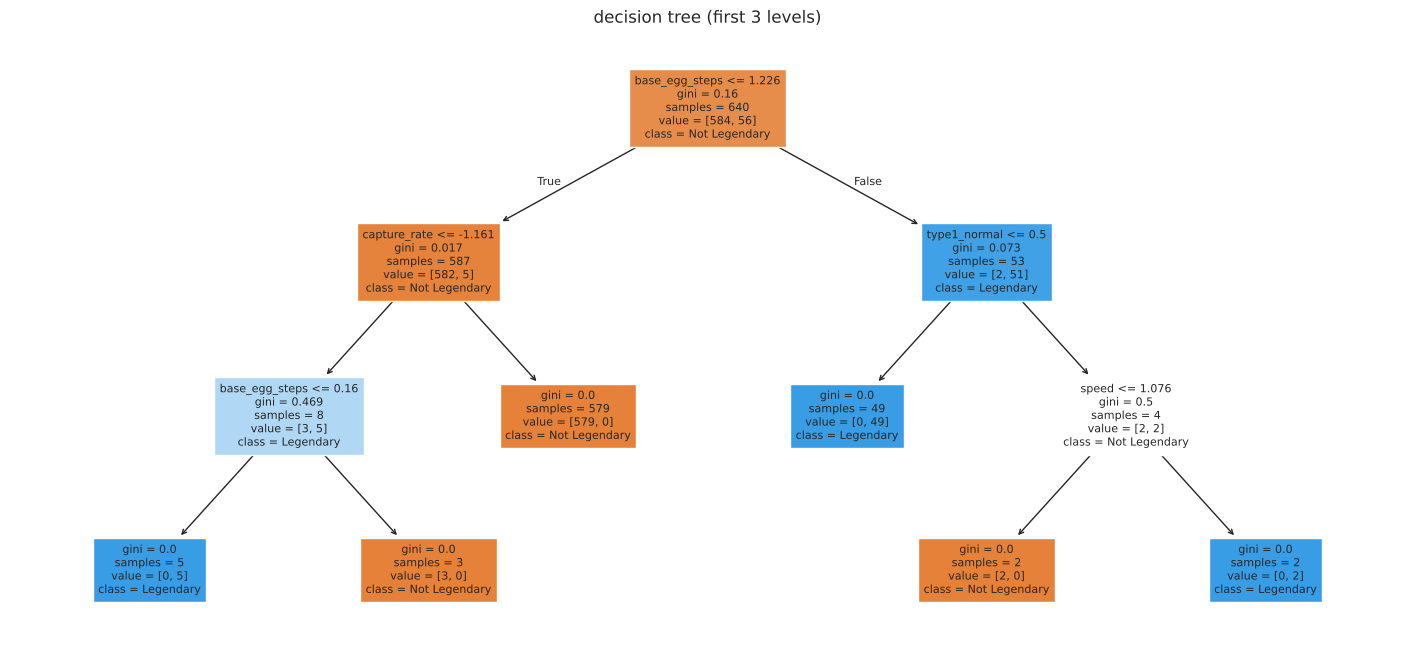

In [26]:
def clean_names(pipe):
    return [n.split("__", 1)[1] for n in pipe.named_steps["prep"].get_feature_names_out()]

# random forest feature importance
rf_pipe = poke_cls_results_b["Random Forest"]["pipe"]
rf_imp = (pd.DataFrame({"Feature": clean_names(rf_pipe),
                        "Importance": rf_pipe.named_steps["clf"].feature_importances_})
          .sort_values("Importance", ascending=False).head(10))

plt.figure(figsize=(8, 4))
plt.barh(rf_imp["Feature"][::-1], rf_imp["Importance"][::-1], color="teal")
plt.title("top 10 feature importances (Random Forest)")
plt.xlabel("importance")
plt.ylabel("feature")
plt.tight_layout()
plt.show()

# decision tree from Part A (top 3 levels only, so it stays readable)
dt_pipe = poke_cls_results["Decision Tree Classifier"]["pipe"]
plt.figure(figsize=(18, 8))
plot_tree(dt_pipe.named_steps["clf"], max_depth=3, feature_names=clean_names(dt_pipe),
          class_names=["Not Legendary", "Legendary"], filled=True, fontsize=8)
plt.title("decision tree (first 3 levels)")
plt.show()

In [27]:
top2 = final_cls_df["Model"].head(2).tolist()
cv_rows = []
for name in top2:
    pipe_cv = all_cls[name]["pipe"]   # cross_val_score clones it, so the fitted model is not affected
    f1_cv = cross_val_score(pipe_cv, Xp_train, yp_train, cv=skf_p, scoring="f1_weighted")
    auc_cv = cross_val_score(pipe_cv, Xp_train, yp_train, cv=skf_p, scoring="roc_auc")
    cv_rows.append({"Model": name,
                    "CV F1 (weighted) mean": f1_cv.mean(), "CV F1 std": f1_cv.std(),
                    "CV ROC-AUC mean": auc_cv.mean(), "CV ROC-AUC std": auc_cv.std()})
display(pd.DataFrame(cv_rows).round(4))

,Model,CV F1 (weighted) mean,CV F1 std,CV ROC-AUC mean,CV ROC-AUC std
0,Decision Tree Classifier,0.9858,0.0093,0.9534,0.0443
1,Gradient Boosting,0.9889,0.0097,0.9980,0.0033


In [28]:
param_grids = {
    "Logistic Regression": {"clf__C": [0.01, 0.1, 1, 10, 100]},
    "KNN Classifier": {"clf__n_neighbors": [3, 5, 7, 9, 11], "clf__weights": ["uniform", "distance"]},
    "Naive Bayes": {"clf__var_smoothing": [1e-9, 1e-8, 1e-7, 1e-6]},
    "Decision Tree Classifier": {"clf__max_depth": [3, 5, 7, 10, None], "clf__min_samples_split": [2, 5, 10]},
    "SVC": {"clf__C": [0.1, 1, 10, 100], "clf__kernel": ["linear", "rbf"], "clf__gamma": ["scale", "auto"]},
    "Random Forest": {"clf__n_estimators": [100, 200, 300], "clf__max_depth": [None, 10, 20],
                      "clf__min_samples_split": [2, 5]},
    "AdaBoost": {"clf__n_estimators": [50, 100, 200], "clf__learning_rate": [0.01, 0.1, 0.5, 1.0]},
    "Gradient Boosting": {"clf__n_estimators": [100, 200], "clf__learning_rate": [0.05, 0.1, 0.2],
                          "clf__max_depth": [2, 3, 4]},
    "Bagging (Decision Tree)": {"clf__n_estimators": [10, 50, 100], "clf__max_samples": [0.5, 0.8, 1.0],
                                "clf__max_features": [0.8, 1.0]},
    "MLP Classifier": {"clf__hidden_layer_sizes": [(32,), (64, 32), (128, 64)],
                       "clf__activation": ["relu", "tanh"], "clf__alpha": [1e-4, 1e-3, 1e-2]},
}

FINAL_MODEL = None   # e.g. "Random Forest"; None = best model from the table
final_name = FINAL_MODEL or final_cls_df.loc[1, "Model"]
print(f"tuning: {final_name}")

grid_cls = GridSearchCV(clone(all_cls[final_name]["pipe"]), param_grids[final_name],
                        cv=skf_p, scoring="f1_weighted", n_jobs=-1)
grid_cls.fit(Xp_train, yp_train)
best_cls = grid_cls.best_estimator_

print("best params:", grid_cls.best_params_)
print(f"best CV weighted F1: {grid_cls.best_score_:.4f}")

before = evaluate_model(f"{final_name} (baseline)", part_of[final_name], all_cls[final_name]["pipe"], Xp_test, yp_test)
after = evaluate_model(f"{final_name} (tuned)", part_of[final_name], best_cls, Xp_test, yp_test)
tune_df = pd.DataFrame([before, after]).drop(columns="Part").set_index("Model")
tune_df.loc["delta"] = tune_df.iloc[1] - tune_df.iloc[0]
display(tune_df.round(4))

tuning: Decision Tree Classifier


best params: {'clf__max_depth': 3, 'clf__min_samples_split': 2}
best CV weighted F1: 0.9858


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,F1 (Legendary)
Model,,,,,,
Decision Tree Classifier (baseline),1.0,1.0,1.0,1.0,1.0,1.0
Decision Tree Classifier (tuned),1.0,1.0,1.0,1.0,1.0,1.0
delta,0.0,0.0,0.0,0.0,0.0,0.0


In [29]:
# optional: save the tuned model (models/ folder in the repo); also useful for the Streamlit/Gradio bonus
import joblib
os.makedirs("models", exist_ok=True)
joblib.dump(best_cls, "models/pokemon_legendary_classifier.pkl")
print("saved models/pokemon_legendary_classifier.pkl")

saved models/pokemon_legendary_classifier.pkl


In [30]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import linkage, dendrogram

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
PALETTE = sns.color_palette("colorblind")   # colourblind-friendly


def cluster_metrics(X_, labels_):
    # Silhouette and Calinski-Harabasz: higher is better; Davies-Bouldin: lower is better
    return {"Silhouette": silhouette_score(X_, labels_),
            "Davies-Bouldin": davies_bouldin_score(X_, labels_),
            "Calinski-Harabasz": calinski_harabasz_score(X_, labels_)}


def plot_clusters(ax, coords, labels, title, xlabel, ylabel):
    for c in sorted(set(labels)):
        m = labels == c
        ax.scatter(coords[m, 0], coords[m, 1], s=35, alpha=0.8, color=PALETTE[c % len(PALETTE)],
                   edgecolor="white", linewidth=0.4, label=f"cluster {c} (n={m.sum()})")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=8)

In [31]:
DATA_FILE = "starbucks_drinkMenu_expanded.csv"
path = next((p for p in [DATA_FILE, f"data/{DATA_FILE}", f"../data/{DATA_FILE}"] if os.path.exists(p)), None)
if path is None:
    raise FileNotFoundError(f"{DATA_FILE} not found. Put it in the data/ folder.")

raw = pd.read_csv(path)
print("shape:", raw.shape)
display(raw.head())
print("\ndtypes:")
print(raw.dtypes)
print("\nmissing values per column:")
print(raw.isna().sum())
print("\nduplicate rows:", raw.duplicated().sum())

shape: (242, 18)


,Beverage_category,Beverage,Beverage_prep,Calories,Total Fat (g),Trans Fat (g),Saturated Fat (g),Sodium (mg),Total Carbohydrates (g),Cholesterol (mg),Dietary Fibre (g),Sugars (g),Protein (g),Vitamin A (% DV),Vitamin C (% DV),Calcium (% DV),Iron (% DV),Caffeine (mg)
0,Coffee,Brewed Coffee,Short,3,0.1,0.0,0.0,0,5,0,0,0,0.3,0%,0%,0%,0%,175
1,Coffee,Brewed Coffee,Tall,4,0.1,0.0,0.0,0,10,0,0,0,0.5,0%,0%,0%,0%,260
2,Coffee,Brewed Coffee,Grande,5,0.1,0.0,0.0,0,10,0,0,0,1.0,0%,0%,0%,0%,330
3,Coffee,Brewed Coffee,Venti,5,0.1,0.0,0.0,0,10,0,0,0,1.0,0%,0%,2%,0%,410
4,Classic Espresso Drinks,Caffè Latte,Short Nonfat Milk,70,0.1,0.1,0.0,5,75,10,0,9,6.0,10%,0%,20%,0%,75



dtypes:
Beverage_category                str
Beverage                         str
Beverage_prep                    str
Calories                       int64
 Total Fat (g)                   str
Trans Fat (g)                float64
Saturated Fat (g)            float64
 Sodium (mg)                   int64
 Total Carbohydrates (g)       int64
Cholesterol (mg)               int64
 Dietary Fibre (g)             int64
 Sugars (g)                    int64
 Protein (g)                 float64
Vitamin A (% DV)                 str
Vitamin C (% DV)                 str
 Calcium (% DV)                  str
Iron (% DV)                      str
Caffeine (mg)                    str
dtype: object

missing values per column:
Beverage_category            0
Beverage                     0
Beverage_prep                0
Calories                     0
 Total Fat (g)               0
Trans Fat (g)                0
Saturated Fat (g)            0
 Sodium (mg)                 0
 Total Carbohydrates (g)     0
Chol

In [32]:
def tidy_name(c):
    c = re.sub(r"\(.*?\)", "", str(c))                   # drop units like (g), (mg), (% DV)
    return re.sub(r"[^a-z0-9]+", "_", c.strip().lower()).strip("_")

df = raw.copy()
df.columns = [tidy_name(c) for c in df.columns]

numeric_cols = []
for col in df.columns:
    s = df[col].astype(str).str.replace("%", "", regex=False).str.strip()
    s = s.str.replace(r"^(\d+)\s+(\d+)$", r"\1.\2", regex=True)       # typo "3 2" -> "3.2"
    converted = pd.to_numeric(s, errors="coerce")                      # "Varies" becomes NaN
    if converted.notna().mean() >= 0.6:                                # mostly numeric -> clustering feature
        df[col] = converted
        numeric_cols.append(col)

print("features used for clustering:", numeric_cols)
n_missing = df[numeric_cols].isna().sum()
print("\nmissing after conversion:")
print(n_missing[n_missing > 0])

features used for clustering: ['calories', 'total_fat', 'trans_fat', 'saturated_fat', 'sodium', 'total_carbohydrates', 'cholesterol', 'dietary_fibre', 'sugars', 'protein', 'vitamin_a', 'vitamin_c', 'calcium', 'iron', 'caffeine']

missing after conversion:
caffeine    23
dtype: int64


In [33]:
bad_sugar = int((df["sugars"] > df["total_carbohydrates"]).sum())
bad_fat = int((df["trans_fat"] > df["saturated_fat"]).sum())
print(f"as labelled : sugars > carbs in {bad_sugar} rows, trans fat > saturated fat in {bad_fat} rows (both impossible)")

if bad_sugar > 0 or bad_fat > 0:
    # actual data order: saturated fat, trans fat, cholesterol, sodium, total carbohydrates
    df = df.rename(columns={"trans_fat": "saturated_fat", "saturated_fat": "trans_fat",
                            "sodium": "cholesterol", "total_carbohydrates": "sodium",
                            "cholesterol": "total_carbohydrates"})
    bad_sugar = int((df["sugars"] > df["total_carbohydrates"]).sum())
    bad_fat = int((df["trans_fat"] > df["saturated_fat"]).sum())
    print(f"after fixing: sugars > carbs in {bad_sugar} rows, trans fat > saturated fat in {bad_fat} rows")

df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())   # median is robust and uses no labels
print("clean feature matrix:", df[numeric_cols].shape)

as labelled : sugars > carbs in 13 rows, trans fat > saturated fat in 209 rows (both impossible)
after fixing: sugars > carbs in 0 rows, trans fat > saturated fat in 0 rows
clean feature matrix: (242, 15)


In [34]:
X_scaled = StandardScaler().fit_transform(df[numeric_cols].values)

pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)
evr = pca.explained_variance_ratio_
print(f"PC1 explains {evr[0]:.1%}, PC2 explains {evr[1]:.1%} of the variance")

PC1 explains 42.0%, PC2 explains 16.5% of the variance


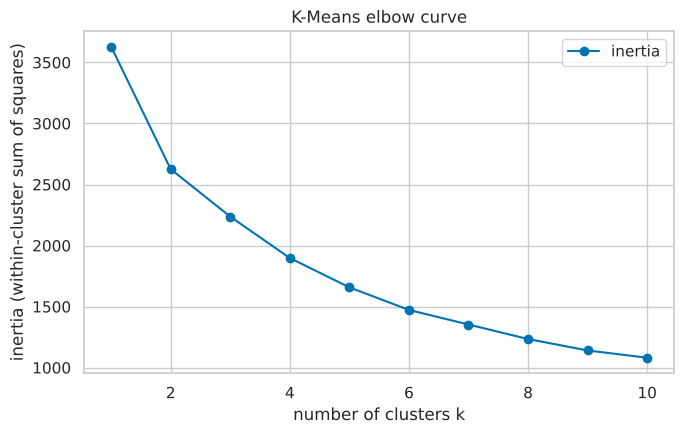

In [35]:
# elbow curve: inertia for k = 1..10
ks = range(1, 11)
inertias = [KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_scaled).inertia_ for k in ks]

plt.figure(figsize=(7, 4.5))
plt.plot(list(ks), inertias, "o-", color=PALETTE[0], label="inertia")
plt.title("K-Means elbow curve")
plt.xlabel("number of clusters k")
plt.ylabel("inertia (within-cluster sum of squares)")
plt.legend()
plt.tight_layout()
plt.show()

In [36]:
K_CHOSEN = 5    # chosen from the elbow curve above; change it if you read the elbow differently

kmeans = KMeans(n_clusters=K_CHOSEN, n_init=10, random_state=SEED).fit(X_scaled)
km_labels = kmeans.labels_
print("K-Means cluster sizes:", np.bincount(km_labels).tolist())

K-Means cluster sizes: [120, 43, 6, 31, 42]


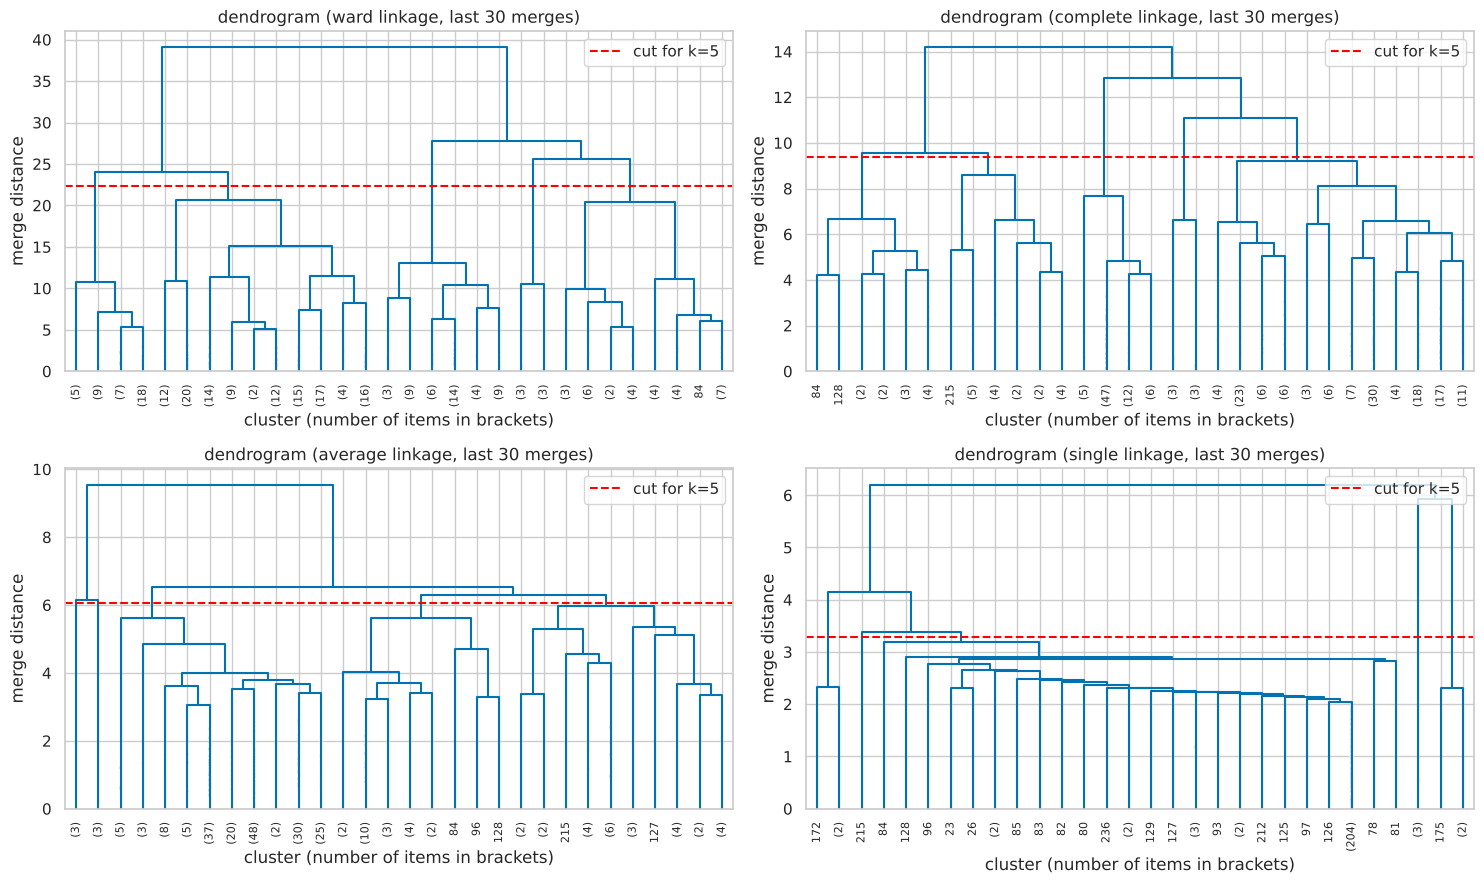

In [37]:
linkages = ["ward", "complete", "average", "single"]
Z = {m: linkage(X_scaled, method=m) for m in linkages}

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, m in zip(axes.ravel(), linkages):
    dendrogram(Z[m], truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=8,
               show_contracted=True, color_threshold=0, above_threshold_color=PALETTE[0], ax=ax)
    cut = (Z[m][-K_CHOSEN, 2] + Z[m][-(K_CHOSEN - 1), 2]) / 2
    ax.axhline(cut, color="red", ls="--", label=f"cut for k={K_CHOSEN}")
    ax.set_title(f"dendrogram ({m} linkage, last 30 merges)")
    ax.set_xlabel("cluster (number of items in brackets)")
    ax.set_ylabel("merge distance")
    ax.legend()
plt.tight_layout()
plt.show()

In [38]:
link_rows = []
for m in linkages:
    lab = AgglomerativeClustering(n_clusters=K_CHOSEN, linkage=m).fit_predict(X_scaled)
    link_rows.append({"Linkage": m, **cluster_metrics(X_scaled, lab),
                      "Cluster sizes": str(np.bincount(lab).tolist())})
display(pd.DataFrame(link_rows).set_index("Linkage").round(3))

HIER_LINKAGE = "ward"    # pick using the table above and justify it below
agg_labels = AgglomerativeClustering(n_clusters=K_CHOSEN, linkage=HIER_LINKAGE).fit_predict(X_scaled)
print("linkage used:", HIER_LINKAGE)

,Silhouette,Davies-Bouldin,Calinski-Harabasz,Cluster sizes
Linkage,,,,
ward,0.181,1.371,56.207,"[121, 31, 45, 6, 39]"
complete,0.143,1.437,49.927,"[135, 18, 70, 6, 13]"
average,0.361,1.041,47.987,"[29, 24, 183, 3, 3]"
single,0.289,0.604,11.945,"[232, 3, 3, 3, 1]"


linkage used: ward


In [39]:
results = {"K-Means": km_labels, f"Agglomerative ({HIER_LINKAGE})": agg_labels}

eval_df = pd.DataFrame([{"Algorithm": name, "Clusters": len(set(lab)),
                         **cluster_metrics(X_scaled, lab),
                         "Cluster sizes": str(np.bincount(lab).tolist())}
                        for name, lab in results.items()]).set_index("Algorithm")
display(eval_df.round(4))

,Clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz,Cluster sizes
Algorithm,,,,,
K-Means,5,0.2846,1.2741,70.5011,"[120, 43, 6, 31, 42]"
Agglomerative (ward),5,0.1809,1.3713,56.2067,"[121, 31, 45, 6, 39]"


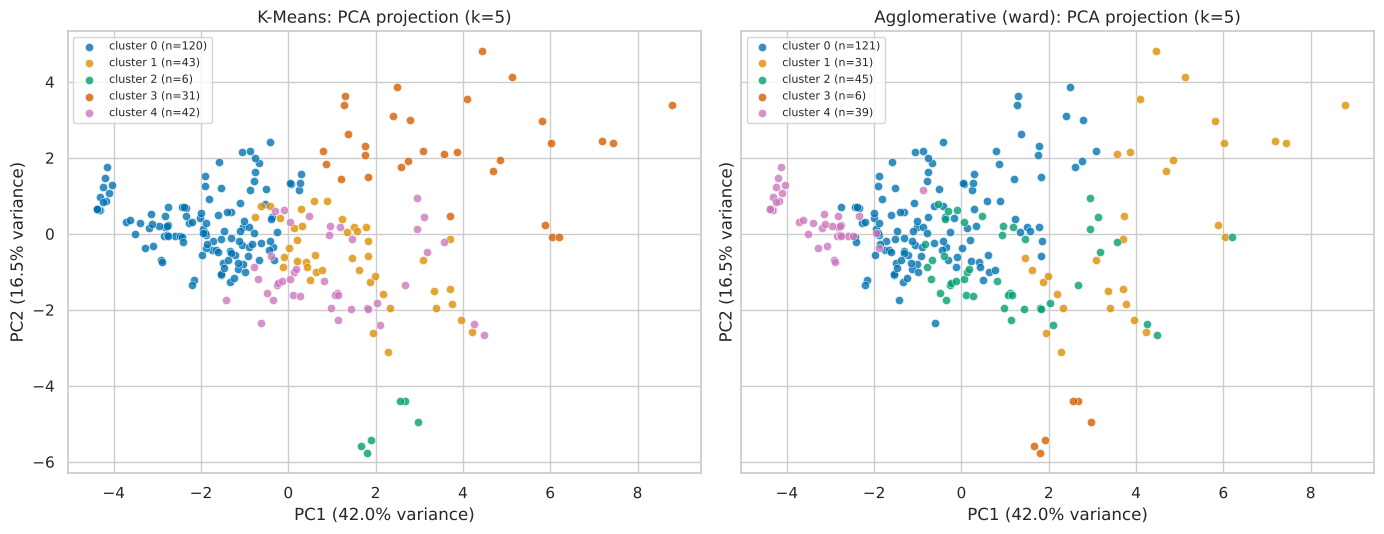

In [40]:
# PCA 2D scatter for every algorithm
fig, axes = plt.subplots(1, len(results), figsize=(7 * len(results), 5.5), sharex=True, sharey=True)
for ax, (name, lab) in zip(axes, results.items()):
    plot_clusters(ax, X_pca, lab, f"{name}: PCA projection (k={K_CHOSEN})",
                  f"PC1 ({evr[0]:.1%} variance)", f"PC2 ({evr[1]:.1%} variance)")
plt.tight_layout()
plt.show()

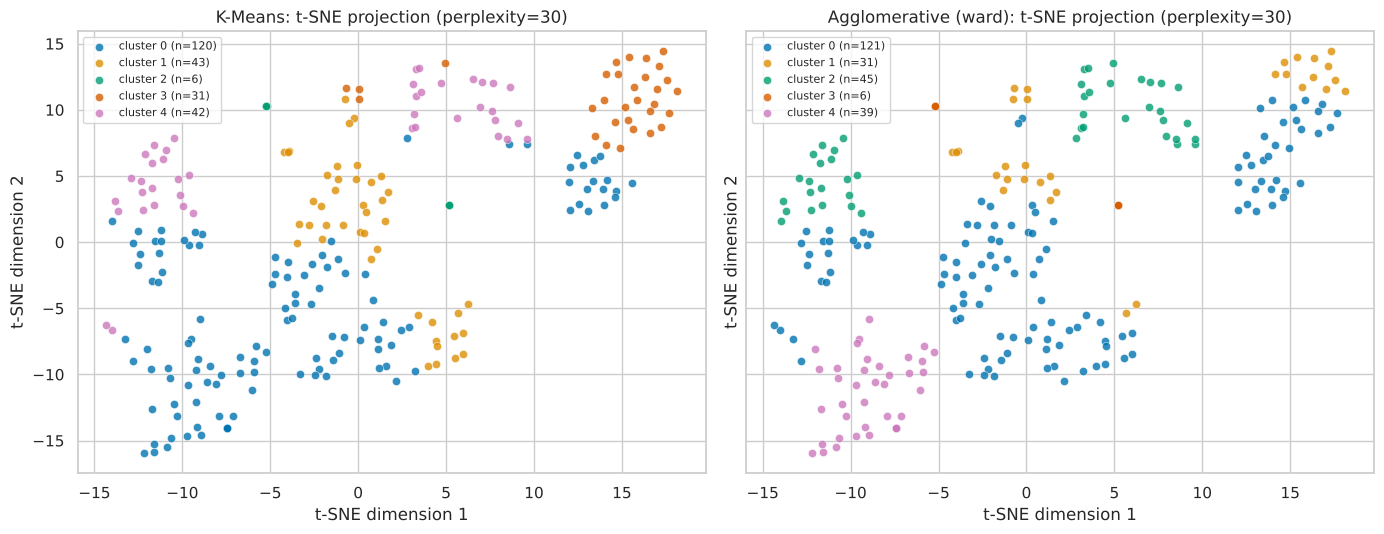

In [41]:
# t-SNE
perplexity = min(30, max(5, (len(X_scaled) - 1) // 3))
X_tsne = TSNE(n_components=2, perplexity=perplexity, init="pca", random_state=SEED).fit_transform(X_scaled)

fig, axes = plt.subplots(1, len(results), figsize=(7 * len(results), 5.5), sharex=True, sharey=True)
for ax, (name, lab) in zip(axes, results.items()):
    plot_clusters(ax, X_tsne, lab, f"{name}: t-SNE projection (perplexity={perplexity})",
                  "t-SNE dimension 1", "t-SNE dimension 2")
plt.tight_layout()
plt.show()

## 6. Apps

This cell saves the trained regression and clustering models next to the classifier (`models/`) and builds `ui.html`, an offline page with the results dashboard and a **Try it** tab. The **Streamlit app** in `app/app.py` loads the same saved models: run `streamlit run app/app.py` from the repo root.

In [42]:
import joblib
os.makedirs("models", exist_ok=True)
joblib.dump(best_overall, "models/coaster_speed_regressor.pkl")
joblib.dump(kmeans, "models/starbucks_kmeans.pkl")

# everything the Streamlit app needs to assign a new drink to a cluster
items = df[["beverage", "beverage_prep"] + numeric_cols].copy()
items.insert(0, "label", items["beverage"].astype(str) + " (" + items["beverage_prep"].astype(str) + ")")
joblib.dump({"kmeans": kmeans, "scaler": StandardScaler().fit(df[numeric_cols].values),
             "features": numeric_cols, "items": items[["label"] + numeric_cols]}, "models/starbucks_clustering.pkl")

from app.export_ui import build_ui
build_ui(globals())   # writes ui.html (offline page) in the repo root

wrote ui.html (333 KB)
